# Hotel Luxury — Semana ML avanzado: patrones no supervisados

**Experimento independiente** a partir de una serie diaria sintética reproducible. No reproduce ni modifica las 12 282 reservas del proyecto original. La salida es cantidad de habitaciones ocupadas (no porcentaje).

## 1. Objetivo y conocimientos nuevos

1. Identificar segmentos de comportamiento histórico con K-Means.
2. Estandarizar variables y seleccionar k mediante Silhouette calculado exclusivamente sobre entrenamiento.
3. Evaluar el aporte de los clusters como variable adicional del Random Forest, manteniendo idénticas particiones e hiperparámetros.

In [1]:
from pathlib import Path
import subprocess
import sys
from urllib.request import urlopen

SOURCE = Path("src/experimento_clusters.py")
REPOSITORY = "https://raw.githubusercontent.com/tmpDash/UPN-Dev-Hostel/main/ml/kmeans"

cwd = Path.cwd().resolve()
candidates = (root for parent in (cwd, *cwd.parents) for root in (parent, parent / "ml/kmeans"))
ROOT = next((path for path in candidates if (path / SOURCE).is_file()), None)

if ROOT is None:
    try:
        import google.colab
    except ImportError:
        raise FileNotFoundError("Abre el notebook dentro de la copia de UPN-Dev-Hostel.") from None

    ROOT = cwd / "hotel_luxury_kmeans"
    for relative in (SOURCE, Path("requirements.txt")):
        destination = ROOT / relative
        destination.parent.mkdir(parents=True, exist_ok=True)
        with urlopen(f"{REPOSITORY}/{relative.as_posix()}", timeout=30) as response:
            destination.write_bytes(response.read())
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")],
        check=True,
    )

sys.path.insert(0, str(ROOT / "src"))
from experimento_clusters import experimento

print("Experimento K-Means preparado.")

Experimento K-Means preparado.


## 2. Dataset, entrenamiento y evaluación

La serie de demostración cubre 2024-01-01 a 2026-10-31 (capacidad 180 habitaciones). Se construyen variables históricas desplazadas para evitar acceso al objetivo futuro. Se reserva un test cronológico y se exige que cada etiqueta de entrenamiento ya sea conocida antes del corte. El k se selecciona en entrenamiento por silhouette; el preprocesamiento y K-Means se ajustan sin usar el test.

In [2]:
metricas, seleccion_k, perfiles = experimento()
metricas

 horizonte            modelo  MAE_habitaciones  RMSE_habitaciones  sesgo_habitaciones  n_test
         7 RF_sin_clustering            6.4840             8.3980              0.5792     180
         7 RF_con_clustering            6.5215             8.5407              0.6734     180
        30 RF_sin_clustering            7.0087             9.0763              0.5498     157
        30 RF_con_clustering            7.0072             9.0826              0.5541     157

Selección de k:
  horizonte  k  silhouette_train  seleccionado
         7  2            0.2444          True
        30  2            0.2424          True

Mejora relativa en MAE (%): {'7': np.float64(-0.578), '30': np.float64(0.021)}


,horizonte,modelo,MAE_habitaciones,RMSE_habitaciones,sesgo_habitaciones,n_test
0,7,RF_sin_clustering,6.4840,8.3980,0.5792,180
1,7,RF_con_clustering,6.5215,8.5407,0.6734,180
2,30,RF_sin_clustering,7.0087,9.0763,0.5498,157
3,30,RF_con_clustering,7.0072,9.0826,0.5541,157


## 3. Silhouette y perfiles de ocupación

Los clusters representan segmentos de comportamiento similar; el número asignado al cluster no tiene interpretación ordinal. Un Silhouette bajo indica grupos relativamente superpuestos.

,horizonte,cluster,dias_train,ocup_media_7,variabilidad_7
0,7,0,388,96.76,10.17
1,7,1,425,114.55,10.42
2,30,0,386,96.71,10.18
3,30,1,404,114.47,10.39


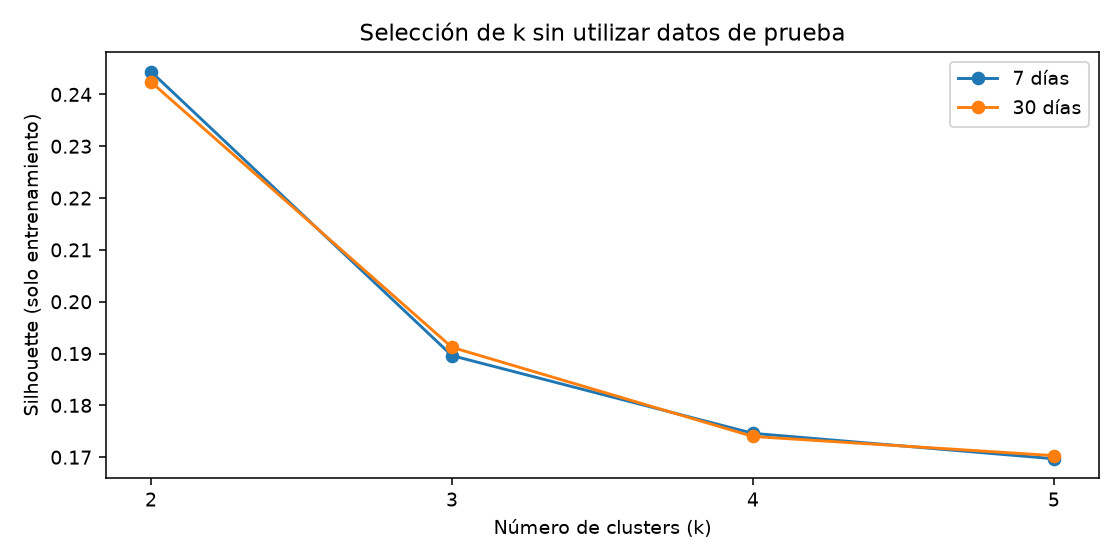

In [3]:
from IPython.display import display, Image
display(perfiles)
display(Image(filename=str(ROOT/"reports"/"silhouette.png")))

## 4. Contraste supervisado (antes/después)

Se compara el mismo Random Forest con/sin cluster. Una reducción de MAE positiva implica mejora y una negativa implica degradación. No atribuir un impacto favorable si no existe.

,horizonte,modelo,MAE_habitaciones,RMSE_habitaciones,sesgo_habitaciones,n_test
0,7,RF_sin_clustering,6.4840,8.3980,0.5792,180
1,7,RF_con_clustering,6.5215,8.5407,0.6734,180
2,30,RF_sin_clustering,7.0087,9.0763,0.5498,157
3,30,RF_con_clustering,7.0072,9.0826,0.5541,157


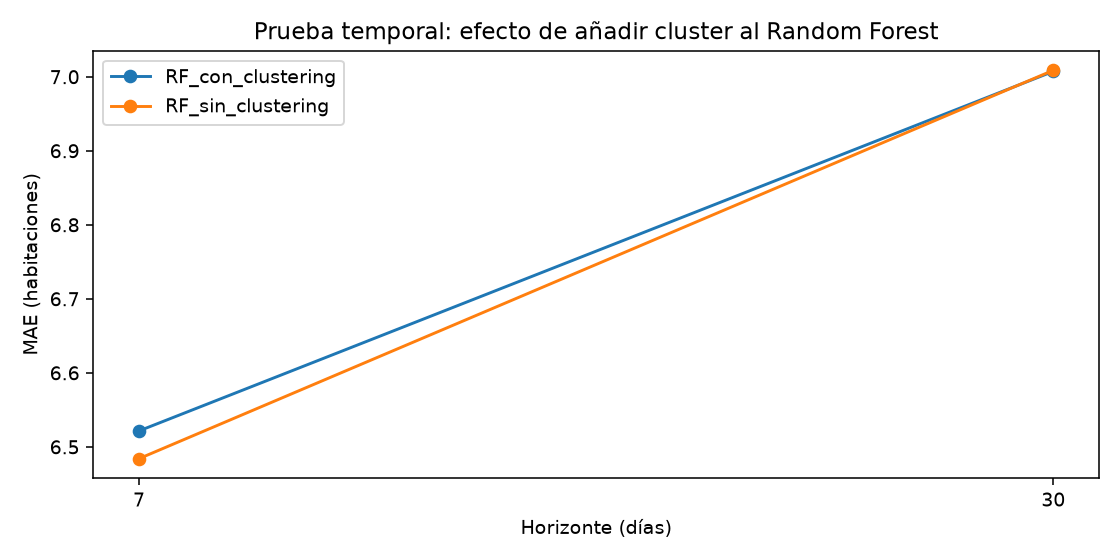

In [4]:
display(metricas)
display(Image(filename=str(ROOT/"reports"/"comparacion_mae.png")))

## 5. Conclusiones, limitaciones y riesgos

**Hallazgos:** el clustering es reproducible y permite extraer segmentos históricos; la utilidad para mejorar el pronóstico debe juzgarse por las métricas de test, no por Silhouette únicamente.

**Limitaciones:** dataset de demostración independiente, sin histórico real de reservas ni reconstrucción de cortes del PMS; la capacidad de generalizar no ha sido demostrada.

**Riesgos:** fuga temporal, cambios de patrones, segmentación inestable, calidad de datos, interpretación indebida de clusters.

**Recomendaciones:** aplicar las mismas funciones sobre la serie diaria generada por el repositorio original, conservar test bloqueado y repetir el estudio con datos reales autorizados antes de integrar.